In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
from scipy.signal import find_peaks
import datetime
import pickle
import multiprocess as mp
import time

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events
from retrieve_cellState import retrieve_cellState

In [2]:
# ── Directory Setup ──────────────────────────────────────────────────────────
DATADIR = Path('../data/Exp_Intermitotic_Times/')

SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

ODE_DIR = Path(Path.home(), 'ECM_mod_output/sweep_ODE_output')
if not ODE_DIR.exists():
    ODE_DIR.mkdir()

IMT_DIR = Path(Path.home(), 'ECM_mod_output/sweep_IMT_output')
if not IMT_DIR.exists():
    IMT_DIR.mkdir()

OVERWRITE    = True
CURDATE      = datetime.datetime.now().strftime('%Y%m%d')
SAVEFILES = True
SET_JPARAM = False
PSO_NUM = 0
treatment = 'DMSO'


integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

if mp.cpu_count() > 1:
    PROCESSES = mp.cpu_count() - 1
if mp.cpu_count() > 10:
    PROCESSES = mp.cpu_count() - int(round(mp.cpu_count()*0.1,0))

print(f'Will use {PROCESSES} cores for multiprocessing')

Will use 14 cores for multiprocessing


In [15]:
# ── Load sampled parameter names ─────────────────────────────────────────────
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [16]:
# ── Import model parameters ───────────────────────────────────────────────────
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [17]:
# ── Set initial concentrations ────────────────────────────────────────────────
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [18]:
initial_concentrations

,Skp2_0,p21_0,p21p_0,cdh1act_0,cdh1inact_0,Myc_0,CycD_0,CycDp21_0,pRb_0,pRbp_0,...,CycEp21_0,CycA_0,CycAp21_0,CycB_0,CycBp21_0,Cdc20_0,BAX_0,BAXmBCL2_0,BH3_0,BH3BCL2_0
0,12,1,16,6,194,139,47,1,5,242,...,3,102,2,17,2,6,186,13,0,7


## Sweep Array Builder

Defines FAK, AKT, and ERK arrays for a 151-point parameter sweep.

| Segment | FAK range | Points |
|---------|-----------|--------|
| Low     | 0 → 0.4   | 51     |
| Mid     | 0.4 → 0.6 | 50     |
| High    | 0.6 → 1.0 | 50     |

AKT and ERK levels are treatment-dependent (`'DMSO'` or `'ERL'`).

In [110]:
def build_sweep_arrays(treatment: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    # FAK: 0 -> 0.4 -> 0.6 -> 1 (151 total)
    FAKs = np.concatenate((
        np.linspace(0, 0.4, 51),
        np.linspace(0.4, 0.6, 51)[1:],
        np.linspace(0.6, 1.0, 51)[1:],
    ))

    # AKT depends on treatment (151 total)
    if treatment == "DMSO":
        AKTs = np.concatenate((
            np.linspace(0, 0.6, 51),
            np.linspace(0.6, 1.0, 51)[1:],
            np.array([1.0] * 50),
        ))
    else:
        AKTs = np.concatenate((
            np.linspace(0, 0.3, 51),
            np.linspace(0.3, 0.6, 51)[1:],
            np.array([0.6] * 50),
        ))

    # ERK constant per treatment (repeated to 151)
    erk_val = 1.0 if treatment == "DMSO" else 0.2 if treatment == "ERL" else 0.1
    ERKs = np.array([erk_val] * 151, dtype=float)

    assert len(FAKs) == len(AKTs) == len(ERKs) == 151
    return AKTs, FAKs, ERKs

In [20]:
# Quick sanity-check: array lengths and boundary values
for tx in ('DMSO', 'ERL', 'LOW'):
    D, E, L = build_sweep_arrays(tx)
    print(f"{tx}: len(FAKs)={len(F)}, FAK[0]={F[0]:.2f}, FAK[-1]={F[-1]:.2f}")
    print(f"      len(AKTs)={len(A)}, AKT[0]={A[0]:.2f}, AKT[-1]={A[-1]:.2f}")
    print(f"      len(ERKs)={len(E)}, ERK[0]={E[0]:.2f}, ERK[-1]={E[-1]:.2f}")
    print()

DMSO: len(FAKs)=151, FAK[0]=0.00, FAK[-1]=0.60
      len(AKTs)=151, AKT[0]=0.00, AKT[-1]=1.00
      len(ERKs)=151, ERK[0]=0.00, ERK[-1]=1.00

ERL: len(FAKs)=151, FAK[0]=0.00, FAK[-1]=0.60
      len(AKTs)=151, AKT[0]=0.00, AKT[-1]=1.00
      len(ERKs)=151, ERK[0]=0.00, ERK[-1]=1.00

LOW: len(FAKs)=151, FAK[0]=0.00, FAK[-1]=0.60
      len(AKTs)=151, AKT[0]=0.00, AKT[-1]=1.00
      len(ERKs)=151, ERK[0]=0.00, ERK[-1]=1.00



In [149]:
def run_odes(AKT, ERK, FAK, val, treatment=treatment, np=np, model=model, ScipyOdeSimulator=ScipyOdeSimulator, find_peaks=find_peaks, Path=Path,
             integrator_options=integrator_options, SET_JPARAM=SET_JPARAM, PSO_num=PSO_NUM, ODE_DIR=ODE_DIR, save=SAVEFILES, overwrite=OVERWRITE): #PSO_num=PSO_num, ii=ii
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    t = np.linspace(0, 2000, 20001)

    sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler="python", integrator_options=integrator_options).run()
    y_out = sim_ode.observables

    peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
    peaks_half = peaks_cdc[peaks_cdc < len(y_out)/2]
    peaks_half2 = peaks_cdc[peaks_cdc > len(y_out)/2]

    if len(peaks_cdc) > 7:
        variable_range=y_out[peaks_cdc[-6]:peaks_cdc[-1]]
    else:
        variable_range = y_out

    tmp = int(val)
    if SET_JPARAM:
        filename = Path(ODE_DIR,f'{treatment}_psoparam_{PSO_num}_{tmp:03}.csv')
    else:
        filename = Path(ODE_DIR,f'{treatment}_range_{tmp:03}.csv')

    if filename.exists() and not overwrite:
        print(f'{filename} exists, skipping')

    if save and not filename.exists() or overwrite:
        print(f'Saving {filename}')
        np.savetxt(filename, variable_range, delimiter=',')

    if len(peaks_half2) > 1:
        IMTs = [t[y] - t[x] for x, y in zip(peaks_half2, peaks_half2[1:])]
        meanIMT = sum(IMTs) / len(IMTs)
    else:
        meanIMT = 0

    return meanIMT

In [77]:
vals=np.linspace(0,150,151)

## ODE Sweep – ERL treatment

In [113]:
treatment = 'ERL'
AKTs, FAKs, ERKs = build_sweep_arrays(treatment)
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]


In [115]:
if SAVEFILES or OVERWRITE:
    start = time.time()
    with mp.Pool(processes = PROCESSES) as p:
        results = p.starmap(run_odes, conds)
    end = time.time()
    print(f'Processing took {round((end - start)/60,2)} minutes')

Processing took 7.55 minutes


In [116]:
if SET_JPARAM:
    filename = Path(IMT_DIR,f'{treatment}_pso_param_{PSO_NUM}_IMT.csv')
else:
    filename = Path(IMT_DIR,f'{treatment}_IMT.csv')
if filename.exists() and not OVERWRITE:
    print(f'{filename} exists, skipping')
if SAVEFILES and not filename.exists() or OVERWRITE:
    print(f'Saving {filename}')
    np.savetxt(filename, results, delimiter=',')

Saving C:\Users\olesk\ECM_mod_output\sweep_IMT_output\ERL_IMT.csv


## ODE Sweep – DMSO treatment

In [122]:
treatment = 'DMSO'
AKTs, FAKs, ERKs = build_sweep_arrays(treatment)
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]


In [124]:
if SAVEFILES or OVERWRITE:
    start = time.time()
    with mp.Pool(processes = PROCESSES) as p:
        results = p.starmap(run_odes, conds)
    end = time.time()
    print(f'Processing took {round((end - start)/60,2)} minutes')

Processing took 6.84 minutes


In [125]:
if SET_JPARAM:
    filename = Path(IMT_DIR,f'{treatment}_pso_param_{PSO_NUM}_IMT.csv')
else:
    filename = Path(IMT_DIR,f'{treatment}_IMT.csv')
if filename.exists() and not OVERWRITE:
    print(f'{filename} exists, skipping')
if SAVEFILES and not filename.exists() or OVERWRITE:
    print(f'Saving {filename}')
    np.savetxt(filename, results, delimiter=',')

Saving C:\Users\olesk\ECM_mod_output\sweep_IMT_output\DMSO_IMT.csv


## ODE Sweep – LOW treatment

In [148]:
treatment = 'LOW'
AKTs, FAKs, ERKs = build_sweep_arrays(treatment)
conds = [(AKT, ERK, FAK, val) for AKT, ERK, FAK, val in zip(AKTs, ERKs, FAKs, vals)]


In [179]:
conds1 = [conds[42], conds[43]]
conds1

[(0.252, 0.1, 0.336, 42.0), (0.258, 0.1, 0.34400000000000003, 43.0)]

In [150]:
if SAVEFILES or OVERWRITE:
    start = time.time()
    with mp.Pool(processes = PROCESSES) as p:
        results = p.starmap(run_odes, conds)
    end = time.time()
    print(f'Processing took {round((end - start)/60,2)} minutes')

Processing took 3.44 minutes


In [152]:
if SET_JPARAM:
    filename = Path(IMT_DIR,f'{treatment}_pso_param_{PSO_NUM}_IMT.csv')
else:
    filename = Path(IMT_DIR,f'{treatment}_IMT.csv')
if filename.exists() and not OVERWRITE:
    print(f'{filename} exists, skipping')
if SAVEFILES and not filename.exists() or OVERWRITE:
    print(f'Saving {filename}')
    np.savetxt(filename, results, delimiter=',')

Saving C:\Users\olesk\ECM_mod_output\sweep_IMT_output\LOW_IMT.csv


## Calculate UMAP

In [3]:
import pandas as pd
import numpy as np
import umap
import glob
import os
import sys
import joblib
from pathlib import Path
import pickle
from scipy.io import readsav

sys.path.insert(0, "cellular_cycle") # add path to the model

# should examine these functions to determine which are best to use (overlapping functionality)
from model_fxns import minmax_scale, stack_sliding_window, calc_minmax, load_sim_output, load_norm_data


In [4]:
# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/')
UMAP_DIR = Path(Path.home(),'ECM_mod_output/sweep_UMAP')
RED_DIR = Path(Path.home(),'ECM_mod_output/UMAP')

if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()
if not UMAP_DIR.exists():
    UMAP_DIR.mkdir()


OVERWRITE = True # Overwrite existing simulation files
SET_JPARAM = False

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

GENERATE_UMAP = False

In [5]:
if SET_JPARAM:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and 'psoparam' in f]
else:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
filenames = sorted(filenames)

filenames_conds = [filenames[2], filenames[3], filenames[0],
                filenames[1], filenames[4], filenames[5]]

filenames_conds


[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]

In [6]:
if SET_JPARAM:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and 'psoparam' in f]
else:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and '_param_cycdi_0_0' in f]

filenames_ode = sorted(filenames_ode)

filenames_conds_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0],
                filenames_ode[1], filenames_ode[4], filenames_ode[5]]

filenames_conds_ode


[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_0.csv')]

In [8]:
sys_type = sys.platform
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32':
    sys_name = 'win'
    r_path_date = '20240301'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux':
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

In [11]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 100
min_d = 0.1

In [12]:

if SET_JPARAM:
    r_name = Path(RED_DIR, 'reducer_psoparams_20240513_0.1_0.1_4_0.5.sav')
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}_{neighbs}_{min_d}.sav'

r_path = Path(RED_DIR,r_name)

if not r_path.exists():
    %env R_DBPATH = {r_dbpath}
    print(f'Reducer file not found, downloading from Dropbox: {r_dbpath}')
    !wget -O $R_PATH $R_DBPATH
print(f'Loading reducer from {r_path}')
reducer = joblib.load(r_path)

Loading reducer from C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5_100_0.1.sav


In [13]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18

    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now

        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]

        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]

    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this

        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]

        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]

    return max_prots, min_prots

In [14]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):

    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')

    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)

        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)

    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp


In [15]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [16]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [17]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [18]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [19]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames)
sp = 1
for n in range(len(filenames)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [20]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [23]:
FILE_LOC = Path(Path.home(),'ECM_mod_output/sweep_ODE_output')

filenames = [Path(FILE_LOC,f) for f in os.listdir(FILE_LOC)]

all_odes = sorted(filenames)

In [24]:
all_odes

[WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_000.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_001.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_002.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_003.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_004.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_005.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_006.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_007.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_008.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_009.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_010.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/DMSO_range_011.csv'),
 Win

In [25]:
SAVE_DIR = Path(Path.home(),'ECM_mod_output/sweep_UMAP')

if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

In [26]:
f = all_odes[344]
f

WindowsPath('C:/Users/olesk/ECM_mod_output/sweep_ODE_output/LOW_range_042.csv')

In [27]:
prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])

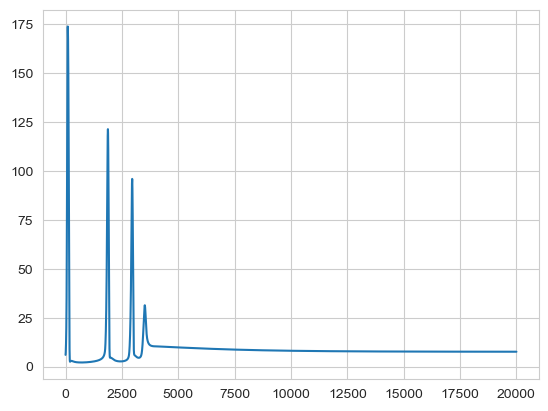

In [28]:
plt.plot(prot_tmp['cdc20'])

In [30]:
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive
all_prot_tmp_ode = np.empty((0,win_len*18))
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
#range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

for f in all_odes:
    # if 'LOW' in str(f):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21",
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])

        range_ind = np.arange(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt))
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(prot_tmp)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            #tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            #tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            #time_re_tmp[ii,:] = np.array([tmp_t])
            #time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        embedding_tmp = reducer.transform(prot_re_tmp)
        absolute_path = f.absolute().as_posix()
        split_s = absolute_path.split('.')
        split_ss = split_s[0].split('/')

        name = 'embedding_'+split_ss[-1]+'.csv'

        np.savetxt(Path(SAVE_DIR, name), embedding_tmp, delimiter=',', fmt='%f')